# Skill Gap Analysis in the AI & Data Job Market
### Demand (job & salary data, 2020-2026) vs Supply

**Status:** complete working notebook - Phase 1 (problem & data), Phase 2 (cleaning), skill mapping, Phase 3 (EDA, 17 figures), Phase 4 (statistics) and Phase 5 (insights).

## 1. Problem statement
Which skills do employers in the AI and data job market ask for, how much of that demand is matched by the skills developers say they already use, and how is the gap expected to change between 2023 (latest observed data) and 2026 (projection)?

## 2. Data sources

 AI Job Market & Salary dataset 2020-2026 -  `ai_job_market_salary_global_2020_2026_01.csv`  
 Stack Overflow Developer Survey  -  `Survay_result.csv` + `survey_results_schema.txt` 


In [2]:
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR    = Path("raw_data")        # folder with the ORIGINAL files (never edit them)
JOBS_FILE   = DATA_DIR / "ai_job_market_salary_global_2020_2026_01.csv"
SURVEY_FILE = DATA_DIR / "Survay_result.csv"
SCHEMA_FILE = DATA_DIR / "survey_results_schema.txt"
OUT_DIR     = Path("cleaned"); OUT_DIR.mkdir(exist_ok=True)   # cleaned copies are saved here

try:
    import pycountry                  # used to turn 2-letter country codes into names
except ImportError:
    pycountry = None
    print("Tip: run  pip install pycountry  to convert country codes (AL, AM, ...) to names.")

# PHASE 1 - Data loading and initial overview
Number of rows and columns, data type of each column, and first observations using `head()`, `info()` and `describe()`.

In [2]:
jobs_raw   = pd.read_csv(JOBS_FILE)
survey_raw = pd.read_csv(SURVEY_FILE, low_memory=False)
schema     = pd.read_csv(SCHEMA_FILE)           # describes each survey column

def overview(df, name):
    """Print the standard first look at a DataFrame."""
    print("=" * 70)
    print(f"{name}: {df.shape[0]:,} rows x {df.shape[1]} columns")
    print("=" * 70)
    df.info(verbose=False)                      # compact info (column list shown separately)
    print("\nMissing values (columns with any):")
    miss = df.isna().sum()
    print(miss[miss > 0].sort_values(ascending=False).head(10).to_string() or "none")
    print(f"\nDuplicate rows: {df.duplicated().sum()}")

overview(jobs_raw, "JOB / SALARY FILE")
display(pd.DataFrame({"dtype": jobs_raw.dtypes.astype(str), "n_unique": jobs_raw.nunique()}))
display(jobs_raw.head())
display(jobs_raw.describe().round(1))

JOB / SALARY FILE: 6,921 rows x 24 columns
<class 'pandas.DataFrame'>
RangeIndex: 6921 entries, 0 to 6920
Columns: 24 entries, job_id to data_note
dtypes: bool(1), int64(2), str(21)
memory usage: 2.9 MB

Missing values (columns with any):
Series([], )

Duplicate rows: 0


,dtype,n_unique
job_id,str,6921
posting_date,str,1955
work_year,int64,7
job_title,str,346
job_title_canonical,str,332
ai_role_category,str,10
experience_level,str,4
employment_type,str,4
salary_usd,int64,3531
salary_currency,str,20


,job_id,posting_date,work_year,job_title,job_title_canonical,ai_role_category,experience_level,employment_type,salary_usd,salary_currency,salary_basis,salary_band,company_location,region,employee_residence,remote_type,company_size,industry,ai_tools_required,yoy_demand_change,high_demand,ai_disruption_risk,data_source,data_note
0,JOB-00001,2023-01-06,2023,Principal Data Scientist,Senior Data Scientist,Data Science,Senior,Full-Time,85847,EUR,Annual (USD),$80K-$120K,Spain,Europe,Spain,Remote,Large (250+),Technology,"R, Python, SAS, Tableau",+7%,False,Medium,ai-jobs.net salary survey,real
1,JOB-00002,2023-07-13,2023,ML Engineer,Machine Learning Engineer,Machine Learning,Mid Level,Contract,30000,USD,Annual (USD),<$50K,United States,North America,United States,Remote,Small (<50),Technology,"Python, LightGBM, CatBoost, Optuna",+25%,True,Low,ai-jobs.net salary survey,real
2,JOB-00003,2023-05-10,2023,ML Engineer,Machine Learning Engineer,Machine Learning,Mid Level,Contract,25500,USD,Annual (USD),<$50K,United States,North America,United States,Remote,Small (<50),Technology,"Python, Spark MLlib, Databricks, MLflow",+25%,True,Low,ai-jobs.net salary survey,real
3,JOB-00004,2023-10-18,2023,Data Scientist,Data Scientist,Data Science,Senior,Full-Time,175000,USD,Annual (USD),$120K-$180K,Canada,North America,Canada,Remote,Medium (50-250),Technology,"Python, Polars, DuckDB, Plotly",+7%,False,Medium,ai-jobs.net salary survey,real
4,JOB-00005,2023-01-26,2023,Data Scientist,Data Scientist,Data Science,Senior,Full-Time,120000,USD,Annual (USD),$120K-$180K,Canada,North America,Canada,Remote,Medium (50-250),Technology,"Python, Scikit-learn, SQL, Power BI",+7%,False,Medium,ai-jobs.net salary survey,real


,work_year,salary_usd
count,6921.0,6921.0
mean,2023.1,150197.4
std,1.8,65261.7
min,2020.0,10000.0
25%,2022.0,103500.0
50%,2023.0,145313.0
75%,2024.0,193987.0
max,2026.0,450068.0


In [3]:
overview(survey_raw, "STACK OVERFLOW SURVEY (sample)")
print("\nFirst 25 column names:", list(survey_raw.columns[:25]))
print("Rows described in schema (full survey size):", int(schema.loc[schema.column == "ResponseId", "nonmissing"].iloc[0]))
display(survey_raw[["ResponseId", "Age", "Country", "Role", "WorkExp", "OrgSize", "WorkSetting", "ConvertedCompYearly"]].head())
display(survey_raw[["YearsCode", "WorkExp", "ConvertedCompYearly"]].apply(pd.to_numeric, errors="coerce").describe().round(1))

STACK OVERFLOW SURVEY (sample): 1,000 rows x 212 columns
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Columns: 212 entries, ResponseId to ConvertedCompYearly
dtypes: float64(14), int64(1), str(197)
memory usage: 6.9 MB

Missing values (columns with any):
JobDifficultyAI_8     1000
JobEaseAI_7           1000
JobDifficultyAI_10    1000
JobDifficultyAI_9     1000
JobEaseAI_10          1000
JobEaseAI_9           1000
KnowledgeSource_14     994
KnowledgeTime_14       994
KnowledgeAcc_14        994
AIMemAdmired           993

Duplicate rows: 0

First 25 column names: ['ResponseId', 'Age', 'CodeMain', 'Education', 'Employment', 'EmploymentAddl', 'ICorPM', 'WorkSetting', 'LearnCode', 'LearnCodeHow', 'LearnAI', 'LearnAIHow', 'YearsCode', 'WorkExp', 'Role', 'RoleFunctions', 'OrgSize', 'TechBudget', 'PurchasePower', 'Industry', 'JobSat', 'JobSatComplacent', 'JobEase', 'JobEaseAI_1', 'JobEaseAI_2']
Rows described in schema (full survey size): 30903


,ResponseId,Age,Country,Role,WorkExp,OrgSize,WorkSetting,ConvertedCompYearly
0,1,35-44 years old,Sri Lanka,"Developer, back-end",NaN,Less than 20 employees,"Hybrid (some remote, leans heavy to in-person)",NaN
1,2,45-54 years old,Brazil,"Developer, full-stack",26.0,"5,000 to 9,999 employees",Remote,NaN
2,3,65 years or older,Ukraine,"Developer, desktop or enterprise applications",37.0,NaN,NaN,10000.0
3,4,Under 18 years old,United States of America,Student,1.0,NaN,NaN,NaN
4,5,45-54 years old,Germany,"Developer, desktop or enterprise applications",26.0,100 to 499 employees,Remote,85296.0


,YearsCode,WorkExp,ConvertedCompYearly
count,980.0,982.0,690.0
mean,22.4,18.0,110192.9
std,13.0,12.8,91048.8
min,1.0,1.0,1.0
25%,12.0,8.0,54768.0
50%,20.0,15.5,93098.0
75%,30.0,26.0,140000.0
max,64.0,100.0,1000000.0


# PHASE 2 - Data cleaning and pre-processing
## 2A. Job file


In [4]:
jobs = jobs_raw.copy()

# 1) Data types: posting_date is text -> datetime
jobs["posting_date"] = pd.to_datetime(jobs["posting_date"], errors="coerce")
print("Unparsed dates:", jobs["posting_date"].isna().sum())
print("posting_date year == work_year for", round((jobs["posting_date"].dt.year == jobs["work_year"]).mean() * 100, 1), "% of rows")

# 2) Duplicates (ignoring the job_id, which is always unique)
print("Duplicate rows (excluding job_id):", jobs.drop(columns="job_id").duplicated().sum())

# 3) Constant columns carry no information -> drop them
const_cols = [c for c in jobs.columns if jobs[c].nunique() == 1]
print("Constant columns dropped:", const_cols)
jobs = jobs.drop(columns=const_cols)

# 4) Period flag: 2020-2023 observed data, 2024-2026 trend-extrapolated projections
jobs["period"] = np.where(jobs["work_year"] <= 2023, "Observed", "Projected")
print(pd.crosstab(jobs["data_note"], jobs["period"]))

Unparsed dates: 0
posting_date year == work_year for 100.0 % of rows
Duplicate rows (excluding job_id): 0
Constant columns dropped: ['salary_basis']
period                                         Observed  Projected
data_note                                                         
2021: limited survey responses in source data       224          0
extrapolated                                          0       2450
real                                               4247          0


In [5]:
# 5) yoy_demand_change: "+7%" -> 7.0
jobs["yoy_demand_pct"] = pd.to_numeric(
    jobs["yoy_demand_change"].str.replace("%", "", regex=False).str.replace("+", "", regex=False),
    errors="coerce")
print("yoy_demand_pct missing after conversion:", jobs["yoy_demand_pct"].isna().sum())

# 6) Salary sanity check (salary_usd is already in USD; salary_currency is the ORIGINAL currency)
print(jobs["salary_usd"].describe().round(0).to_string())

yoy_demand_pct missing after conversion: 0
count      6921.0
mean     150197.0
std       65262.0
min       10000.0
25%      103500.0
50%      145313.0
75%      193987.0
max      450068.0


In [6]:
# 7) Country names: some rows hold 2-letter codes (AL, AM, ...) or "UAE"
def to_country_name(x):
    x = str(x).strip()
    if x == "UAE":
        return "United Arab Emirates"
    if len(x) == 2 and x.isupper() and pycountry is not None:
        match = pycountry.countries.get(alpha_2=x)
        return match.name if match else x
    return x

# Names that differ between pycountry / the survey and the job file -> one standard spelling
NAME_FIX = {
    "United States of America": "United States",
    "United Kingdom of Great Britain and Northern Ireland": "United Kingdom",
    "Russian Federation": "Russia", "Korea, Republic of": "South Korea", "Republic of Korea": "South Korea",
    "Viet Nam": "Vietnam", "Türkiye": "Turkey", "Czech Republic": "Czechia",
    "Hong Kong (S.A.R.)": "Hong Kong", "Iran, Islamic Republic of": "Iran",
    "Iran, Islamic Republic of...": "Iran", "Taiwan, Province of China": "Taiwan",
    "Moldova, Republic of": "Moldova", "Republic of Moldova": "Moldova",
    "United Republic of Tanzania": "Tanzania", "Syrian Arab Republic": "Syria",
    "Venezuela, Bolivarian Republic of": "Venezuela", "Bolivia, Plurinational State of": "Bolivia",
    "Lao People's Democratic Republic": "Laos", "Puerto Rico": "Puerto Rico",
    "Palestine": "Palestine", "State of Palestine": "Palestine",
}
def clean_country(x):
    name = to_country_name(x)
    return NAME_FIX.get(name, name)

jobs["company_country"]  = jobs["company_location"].map(clean_country)
jobs["employee_country"] = jobs["employee_residence"].map(clean_country)
print("Unique company countries:", jobs["company_country"].nunique())
print("Codes still unconverted (length <= 3):", sorted(c for c in jobs["company_country"].unique() if len(c) <= 3))

Unique company countries: 72
Codes still unconverted (length <= 3): []


In [7]:
# 8) Skills: one row per (job, tool). ai_tools_required looks like "Python, SQL, dbt, Tableau"
jobs["tool_list"] = jobs["ai_tools_required"].str.split(",").apply(lambda lst: [t.strip() for t in lst])
jobs["n_tools"]   = jobs["tool_list"].str.len()
tools_long = (jobs[["job_id", "work_year", "period", "ai_role_category", "experience_level", "region",
                    "remote_type", "company_size", "salary_usd", "tool_list"]]
              .explode("tool_list").rename(columns={"tool_list": "tool"}).reset_index(drop=True))
print(f"Jobs: {jobs.shape}  |  tool rows: {tools_long.shape}  |  distinct tools: {tools_long['tool'].nunique()}")
display(tools_long["tool"].value_counts().head(15).rename("job_rows").to_frame())

Jobs: (6921, 29)  |  tool rows: (27714, 10)  |  distinct tools: 195


,job_rows
tool,
Python,5924
SQL,3231
dbt,801
Pandas,676
Scikit-learn,669
Looker,530
Tableau,511
R,485
Databricks,464


## 2B. Survey file


In [8]:
KEEP = ["ResponseId", "Age", "Employment", "Education", "Country", "Industry", "Role", "OrgSize", "WorkSetting",
        "YearsCode", "WorkExp", "ConvertedCompYearly", "AISelect",
        "LanguagesHaveWorkedWith", "DatabasesHaveWorkedWith", "CloudPlatHaveWorkedWith",
        "WebFrameworkHaveWorkedWith", "AIObsHaveWorkedWith", "AIAutomateHaveWorkedWith", "LLMHaveWorkedWith"]
survey = survey_raw[KEEP].copy()
print("Duplicate responses:", survey["ResponseId"].duplicated().sum())

# numbers stored as text -> numeric
for c in ["YearsCode", "WorkExp", "ConvertedCompYearly"]:
    survey[c] = pd.to_numeric(survey[c], errors="coerce")

# Salary: keep realistic annual values only (assumption - change the limits if you wish)
survey["salary_valid"] = survey["ConvertedCompYearly"].between(5_000, 500_000)
print("Salary values outside 5k-500k set to missing:", (~survey["salary_valid"] & survey["ConvertedCompYearly"].notna()).sum())
survey["salary_usd"] = survey["ConvertedCompYearly"].where(survey["salary_valid"])

# Experience groups (ASSUMPTION - the job file gives no year ranges; document your own rule)
survey["experience_level"] = pd.cut(survey["WorkExp"], bins=[-1, 2, 7, 19, 200],
                                    labels=["Entry Level", "Mid Level", "Senior", "Executive"])
print(survey["experience_level"].value_counts(dropna=False).to_string())

Duplicate responses: 0
Salary values outside 5k-500k set to missing: 38
experience_level
Executive      400
Senior         355
Mid Level      146
Entry Level     81
NaN             18


In [9]:
# --- Mapping tables: survey categories -> job-file categories ----------------------------------
ROLE_MAP = {
    "Data scientist": "Data Science",
    "AI/ML engineer": "Machine Learning",
    "Applied scientist": "AI Research",
    "Developer, AI apps or physical AI": "Machine Learning",
    "Data engineer": "Data Engineering",
    "Data or business analyst": "Data Analytics",
    "Cloud infrastructure engineer": "MLOps / AI Infra",
    "DevOps engineer or professional": "MLOps / AI Infra",
    "Platform engineer": "MLOps / AI Infra",
    "Site reliability engineer": "MLOps / AI Infra",
    "Engineering manager": "Leadership",
    "Senior executive (C-suite, VP, etc.)": "Leadership",
}
ORG_MAP = {   # ASSUMPTION: the survey bands do not align exactly with <50 / 50-250 / 250+
    "Just me - I am a freelancer, sole proprietor, etc.": "Small (<50)",
    "Less than 20 employees": "Small (<50)",
    "20 to 99 employees": "Medium (50-250)",
    "100 to 499 employees": "Medium (50-250)",
    "500 to 999 employees": "Large (250+)",
    "1,000 to 4,999 employees": "Large (250+)",
    "5,000 to 9,999 employees": "Large (250+)",
    "10,000 or more employees": "Large (250+)",
}
WORK_MAP = {
    "Remote": "Remote",
    "In-person": "On-site",
    "Hybrid (some remote, leans heavy to in-person)": "Hybrid",
    "Hybrid (some in-person, leans heavy to flexibility)": "Hybrid",
    "Your choice (very flexible, you can come in when you want or just as needed)": "Hybrid",
}
survey["role_group"]    = survey["Role"].map(ROLE_MAP).fillna("Other (not data/AI)")
survey["company_size"]  = survey["OrgSize"].map(ORG_MAP)
survey["remote_type"]   = survey["WorkSetting"].map(WORK_MAP)
survey["country_clean"] = survey["Country"].map(lambda x: clean_country(x) if pd.notna(x) else x)

# Region for survey countries: reuse the job file's own country -> region pairs
country_region = jobs.groupby("company_country")["region"].agg(lambda s: s.mode().iloc[0])
survey["region"] = survey["country_clean"].map(country_region)
print("Survey countries without a region match:", round(survey["region"].isna().mean() * 100, 1), "% of rows (country unknown or not in job file)")
print("Share of survey rows with a data/AI role:", round((survey["role_group"] != "Other (not data/AI)").mean() * 100, 1), "%")
display(survey["role_group"].value_counts().to_frame())

Survey countries without a region match: 4.8 % of rows (country unknown or not in job file)
Share of survey rows with a data/AI role: 13.6 %


,count
role_group,
Other (not data/AI),864
Leadership,37
Machine Learning,26
MLOps / AI Infra,26
Data Engineering,16
Data Science,14
Data Analytics,9
AI Research,8


# Skill mapping and first demand vs supply preview
**Demand** = share of job rows that list the skill. **Supply** = share of survey respondents who answered that survey question and have worked with the skill. **Gap** = demand - supply, in percentage points (positive = demand exceeds supply).

In [10]:
# job-file tool  ->  (survey column, survey option)
SKILL_MAP = {
    "Python":        ("LanguagesHaveWorkedWith",  "Python"),
    "SQL":           ("LanguagesHaveWorkedWith",  "SQL"),
    "R":             ("LanguagesHaveWorkedWith",  "R"),
    "Scala":         ("LanguagesHaveWorkedWith",  "Scala"),
    "BigQuery":      ("DatabasesHaveWorkedWith",  "BigQuery"),
    "Snowflake":     ("DatabasesHaveWorkedWith",  "Snowflake"),
    "DuckDB":        ("DatabasesHaveWorkedWith",  "DuckDB"),
    "Databricks":    ("DatabasesHaveWorkedWith",  "Databricks SQL"),
    "Redshift":      ("DatabasesHaveWorkedWith",  "Amazon Redshift"),
    "FastAPI":       ("WebFrameworkHaveWorkedWith", "FastAPI"),
    "MLflow":        ("AIObsHaveWorkedWith",      "MLflow"),
    "Prefect":       ("AIAutomateHaveWorkedWith", "Prefect"),
}

def has_option(series, option):
    """True where the semicolon-separated answer contains the option."""
    return series.fillna("").str.split(";").apply(lambda lst: option in [x.strip() for x in lst])

def skill_gap(job_rows, survey_rows):
    out = []
    for tool, (col, option) in SKILL_MAP.items():
        demand = job_rows["tool_list"].apply(lambda lst: tool in lst).mean() * 100
        answered = survey_rows[col].notna().sum()
        supply = has_option(survey_rows[col], option).sum() / answered * 100 if answered else np.nan
        out.append({"skill": tool, "demand_pct": demand, "supply_pct": supply,
                    "gap_pp": demand - supply, "survey_n_answered": answered})
    res = pd.DataFrame(out)
    res["low_confidence"] = res["survey_n_answered"] < 150      # few answers -> treat with care
    return res.round(1)

gap_2023 = skill_gap(jobs[jobs["work_year"] == 2023], survey)      # latest OBSERVED year
gap_2026 = skill_gap(jobs[jobs["work_year"] == 2026], survey)      # PROJECTED year
gap = gap_2023.merge(gap_2026[["skill", "demand_pct", "gap_pp"]], on="skill", suffixes=("_2023", "_2026"))
display(gap.sort_values("gap_pp_2023", ascending=False))

,skill,demand_pct_2023,supply_pct,gap_pp_2023,survey_n_answered,low_confidence,demand_pct_2026,gap_pp_2026
0,Python,87.0,56.0,31.0,773,False,81.9,25.9
7,Databricks,8.5,3.5,5.0,695,False,4.1,0.7
5,Snowflake,8.3,3.9,4.4,695,False,3.9,-0.0
2,R,8.1,5.4,2.7,773,False,5.2,-0.3
4,BigQuery,8.2,6.6,1.6,695,False,2.4,-4.3
8,Redshift,3.4,2.7,0.6,695,False,0.7,-2.0
3,Scala,1.7,1.8,-0.1,773,False,0.2,-1.6
11,Prefect,1.9,2.5,-0.6,202,False,0.0,-2.5
6,DuckDB,1.3,6.8,-5.4,695,False,0.0,-6.8
10,MLflow,4.0,15.5,-11.6,103,True,6.5,-9.1


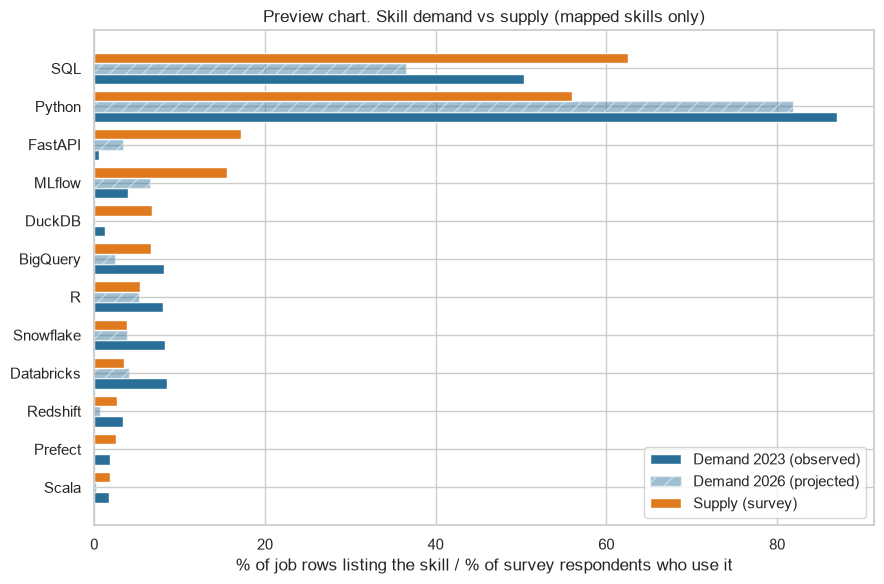

In [11]:
# First visual: demand (2023 observed, 2026 projected) vs supply for each mapped skill
plot_df = gap.sort_values("supply_pct")
y = np.arange(len(plot_df)); h = 0.27
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(y - h, plot_df["demand_pct_2023"], h, label="Demand 2023 (observed)", color="#2a6f97")
ax.barh(y,     plot_df["demand_pct_2026"], h, label="Demand 2026 (projected)", color="#2a6f97", alpha=0.45, hatch="//")
ax.barh(y + h, plot_df["supply_pct"],      h, label="Supply (survey)", color="#e07a1f")
ax.set_yticks(y); ax.set_yticklabels(plot_df["skill"])
ax.set_xlabel("% of job rows listing the skill / % of survey respondents who use it")
ax.set_title("Preview chart. Skill demand vs supply (mapped skills only)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

# PHASE 3 - Exploratory Data Analysis (EDA) and visualisations
Univariate, bivariate and multivariate analysis, using `groupby`, pivot tables and correlation analysis, with statistical summaries to support the findings, and 10+ visuals with titles, labels, legends and subplots.

**Plan for this phase**
- 3.1 **Univariate** - one variable at a time (distributions, shares)
- 3.2 **Bivariate** - two variables (salary vs experience, trends over time, tool premiums)
- 3.3 **Multivariate** - three or more variables (heatmaps, correlation, role mix, demand vs supply gaps)

**Colour code used everywhere:** blue = observed data (2020-2023), orange = projected data (2024-2026), green = survey (supply).

In [12]:
from scipy import stats

EXP_ORDER  = ["Entry Level", "Mid Level", "Senior", "Executive"]
SIZE_ORDER = ["Small (<50)", "Medium (50-250)", "Large (250+)"]

# ordered categories make charts and tables sort in a sensible order
jobs["experience_level"]   = pd.Categorical(jobs["experience_level"], categories=EXP_ORDER, ordered=True)
jobs["company_size"]       = pd.Categorical(jobs["company_size"], categories=SIZE_ORDER, ordered=True)
survey["experience_level"] = pd.Categorical(survey["experience_level"].astype(object), categories=EXP_ORDER, ordered=True)

obs = jobs[jobs["period"] == "Observed"].copy()          # observed rows only (2020-2023)
C_OBS, C_PROJ, C_SUP = "#2a6f97", "#e07a1f", "#6a994e"  # observed / projected / survey colours
PERIOD_PAL = {"Observed": C_OBS, "Projected": C_PROJ}

def shade_projection(ax):
    # grey dashed line at the 2023/2024 boundary and orange shading over projected years
    ax.axvspan(2023.5, 2026.5, color=C_PROJ, alpha=0.10)
    ax.axvline(2023.5, color="gray", ls="--", lw=1)
    ax.text(2023.6, ax.get_ylim()[1], " Projected (modelled)", va="top", fontsize=9, color=C_PROJ)

print("Observed rows:", len(obs), "| Projected rows:", (jobs["period"] == "Projected").sum(), "| Survey respondents:", len(survey))

Observed rows: 4471 | Projected rows: 2450 | Survey respondents: 1000


## 3.1 Univariate analysis


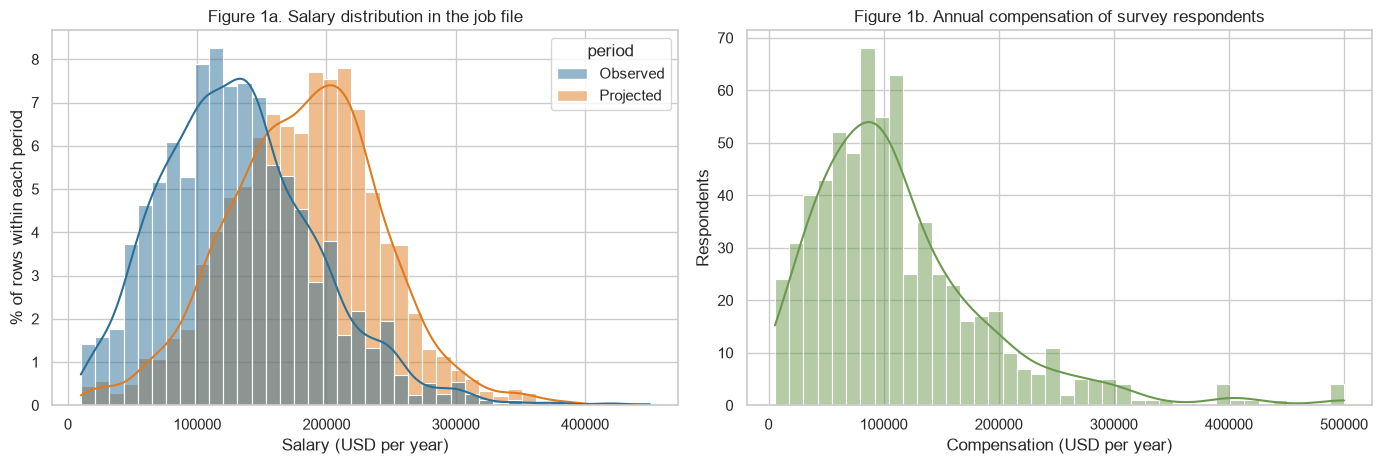

,count,mean,median,std,min,max,skewness
period,,,,,,,
Observed,4471,132191.0,129000.0,60744.0,10000,450000,0.69
Projected,2450,183058.0,185794.0,60230.0,15000,450068,0.07


In [13]:
# Figure 1 - salary distributions (histogram + density curve), job file vs survey
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.histplot(data=jobs, x="salary_usd", hue="period", palette=PERIOD_PAL, bins=40, kde=True,
             stat="percent", common_norm=False, ax=axes[0])
axes[0].set(title="Figure 1a. Salary distribution in the job file", xlabel="Salary (USD per year)", ylabel="% of rows within each period")
sns.histplot(survey["salary_usd"].dropna(), bins=40, kde=True, color=C_SUP, ax=axes[1])
axes[1].set(title="Figure 1b. Annual compensation of survey respondents", xlabel="Compensation (USD per year)", ylabel="Respondents")
plt.tight_layout(); plt.show()

# Statistical summary to support the picture
summary = jobs.groupby("period")["salary_usd"].agg(["count", "mean", "median", "std", "min", "max"]).round(0)
summary["skewness"] = jobs.groupby("period")["salary_usd"].skew().round(2)
display(summary)

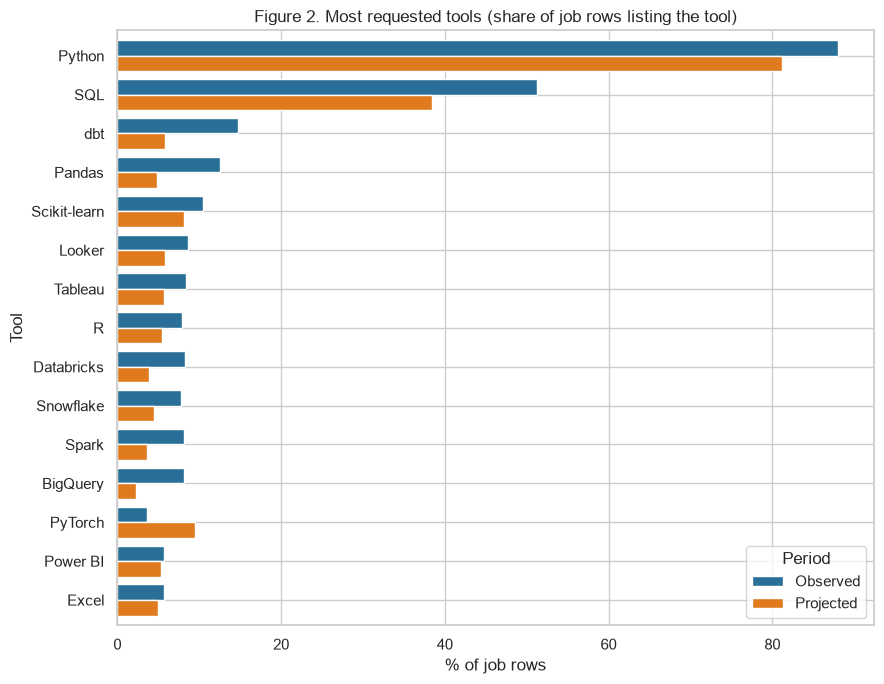

period,Observed,Projected
tool,,
Python,88.0,81.2
SQL,51.2,38.4
dbt,14.7,5.8
Pandas,12.5,4.8
Scikit-learn,10.5,8.1
Looker,8.7,5.8
Tableau,8.3,5.6
R,7.9,5.4
Databricks,8.3,3.8


In [14]:
# Figure 2 - the 15 most common tools: share of job rows listing each tool, observed vs projected
top_tools = tools_long["tool"].value_counts().head(15).index
tool_counts = tools_long[tools_long["tool"].isin(top_tools)].groupby(["tool", "period"]).size().unstack(fill_value=0)
tool_share = tool_counts.div(jobs["period"].value_counts(), axis=1).mul(100).loc[top_tools]

ax = tool_share.plot(kind="barh", color=[C_OBS, C_PROJ], figsize=(9, 7), width=0.8)
ax.invert_yaxis()
ax.set(title="Figure 2. Most requested tools (share of job rows listing the tool)",
       xlabel="% of job rows", ylabel="Tool")
ax.legend(title="Period", loc="lower right")
plt.tight_layout(); plt.show()
display(tool_share.round(1))

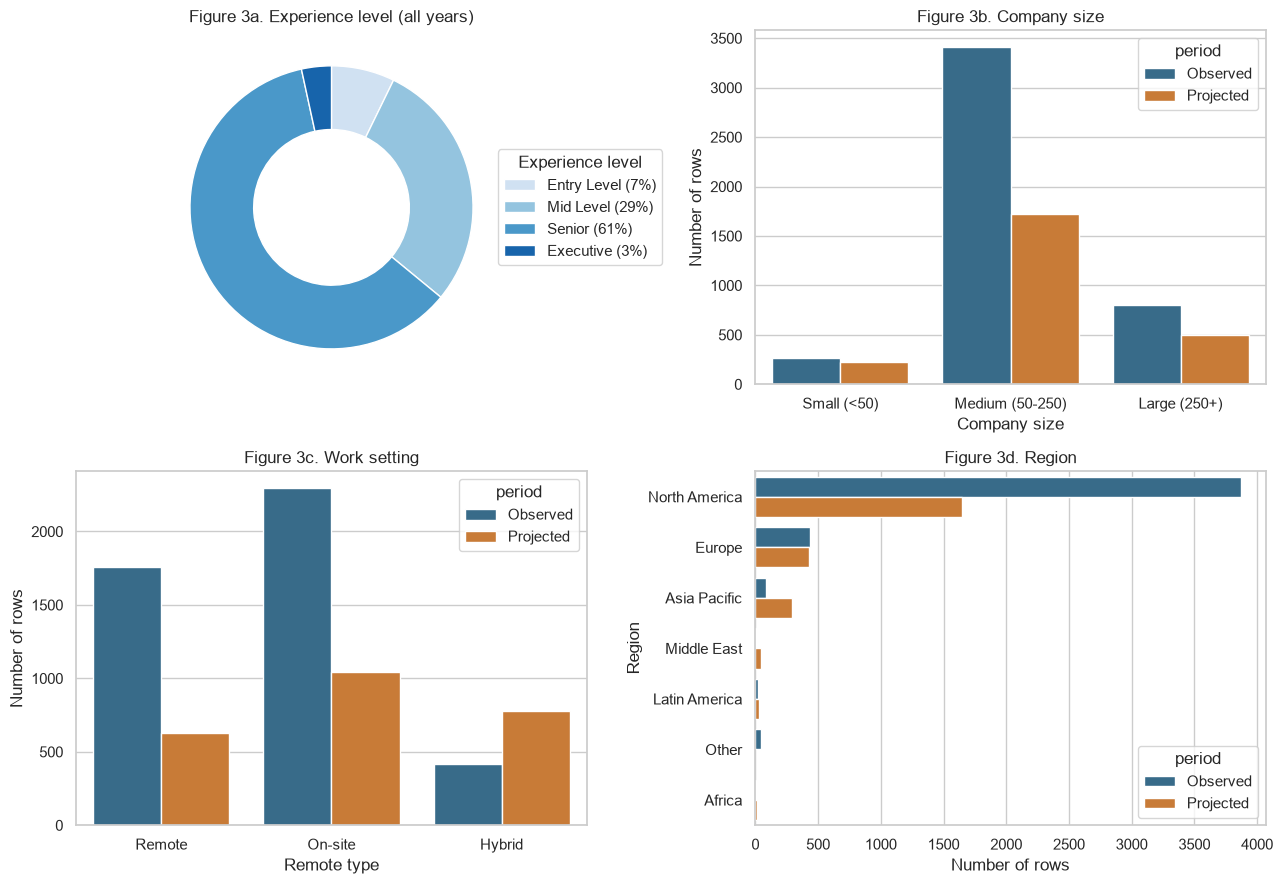

In [15]:
# Figure 3 - composition of the job file (2x2 subplot grid)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

exp_counts = jobs["experience_level"].value_counts().reindex(EXP_ORDER)
axes[0, 0].pie(exp_counts, startangle=90, counterclock=False, wedgeprops=dict(width=0.45),
               colors=sns.color_palette("Blues", 4))
axes[0, 0].legend([f"{lvl} ({v / exp_counts.sum():.0%})" for lvl, v in exp_counts.items()],
                  title="Experience level", loc="center left", bbox_to_anchor=(0.95, 0.5))
axes[0, 0].set_title("Figure 3a. Experience level (all years)")

sns.countplot(data=jobs, x="company_size", order=SIZE_ORDER, hue="period", palette=PERIOD_PAL, ax=axes[0, 1])
axes[0, 1].set(title="Figure 3b. Company size", xlabel="Company size", ylabel="Number of rows")

sns.countplot(data=jobs, x="remote_type", hue="period", palette=PERIOD_PAL, ax=axes[1, 0])
axes[1, 0].set(title="Figure 3c. Work setting", xlabel="Remote type", ylabel="Number of rows")

sns.countplot(data=jobs, y="region", order=jobs["region"].value_counts().index, hue="period", palette=PERIOD_PAL, ax=axes[1, 1])
axes[1, 1].set(title="Figure 3d. Region", xlabel="Number of rows", ylabel="Region")
axes[1, 1].legend(title="period", loc="lower right")
plt.tight_layout(); plt.show()

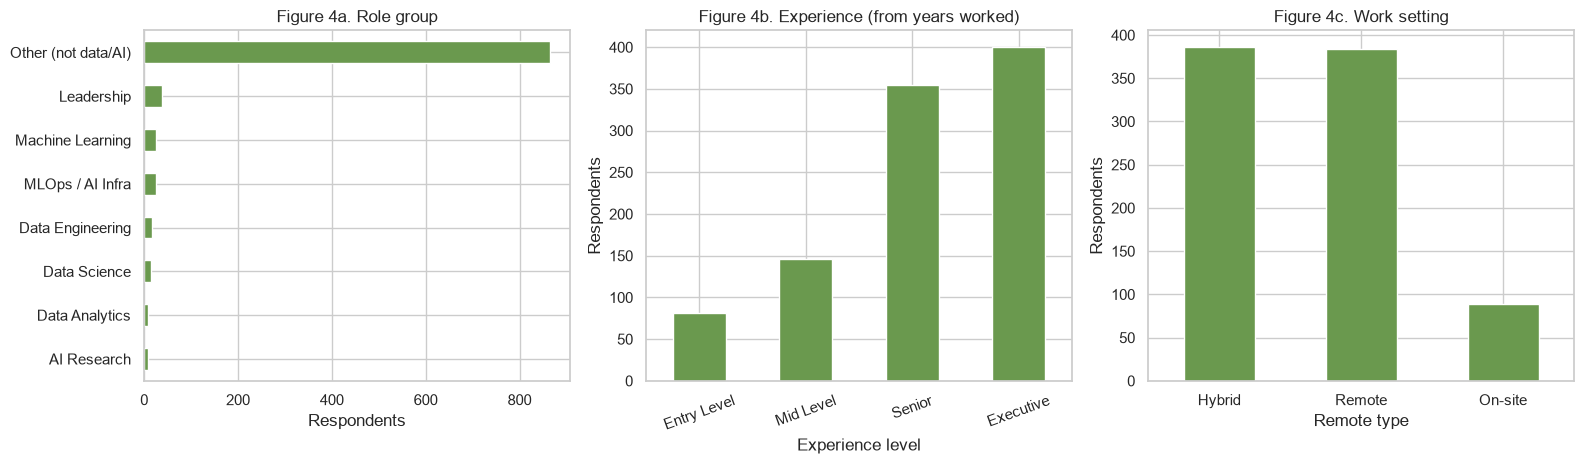

In [16]:
# Figure 4 - composition of the survey sample (supply side)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
survey["role_group"].value_counts().plot(kind="barh", color=C_SUP, ax=axes[0])
axes[0].invert_yaxis(); axes[0].set(title="Figure 4a. Role group", xlabel="Respondents", ylabel="")
survey["experience_level"].value_counts().reindex(EXP_ORDER).plot(kind="bar", color=C_SUP, ax=axes[1])
axes[1].set(title="Figure 4b. Experience (from years worked)", xlabel="Experience level", ylabel="Respondents")
axes[1].tick_params(axis="x", rotation=20)
survey["remote_type"].value_counts().plot(kind="bar", color=C_SUP, ax=axes[2])
axes[2].set(title="Figure 4c. Work setting", xlabel="Remote type", ylabel="Respondents")
axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## 3.2 Bivariate analysis

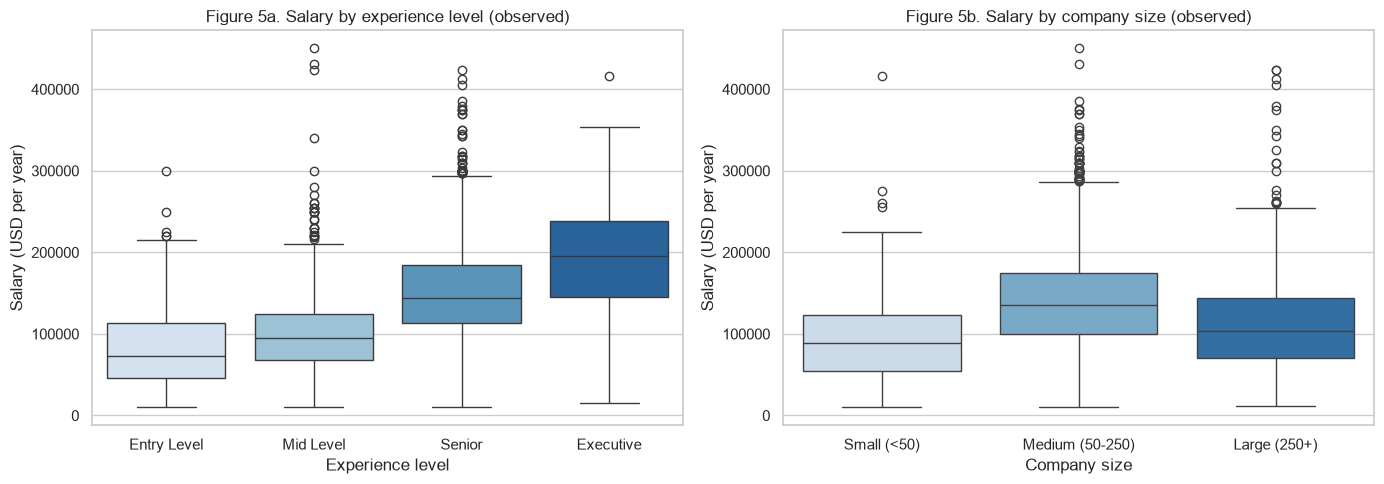

,count,median,mean
experience_level,,,
Entry Level,310,72750.0,81335.0
Mid Level,1314,95000.0,100307.0
Senior,2733,144000.0,150672.0
Executive,114,196000.0,194931.0


,count,median,mean
company_size,,,
Small (<50),266,88369.0,94611.0
Medium (50-250),3408,135000.0,139792.0
Large (250+),797,103000.0,112231.0


In [17]:
# Figure 5 - salary by experience level and by company size (box plots, observed data)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=obs, x="experience_level", y="salary_usd", order=EXP_ORDER, palette="Blues", ax=axes[0])
axes[0].set(title="Figure 5a. Salary by experience level (observed)", xlabel="Experience level", ylabel="Salary (USD per year)")
sns.boxplot(data=obs, x="company_size", y="salary_usd", order=SIZE_ORDER, palette="Blues", ax=axes[1])
axes[1].set(title="Figure 5b. Salary by company size (observed)", xlabel="Company size", ylabel="Salary (USD per year)")
plt.tight_layout(); plt.show()

# groupby summary behind the box plots
display(obs.groupby("experience_level", observed=True)["salary_usd"].agg(["count", "median", "mean"]).round(0))
display(obs.groupby("company_size", observed=True)["salary_usd"].agg(["count", "median", "mean"]).round(0))

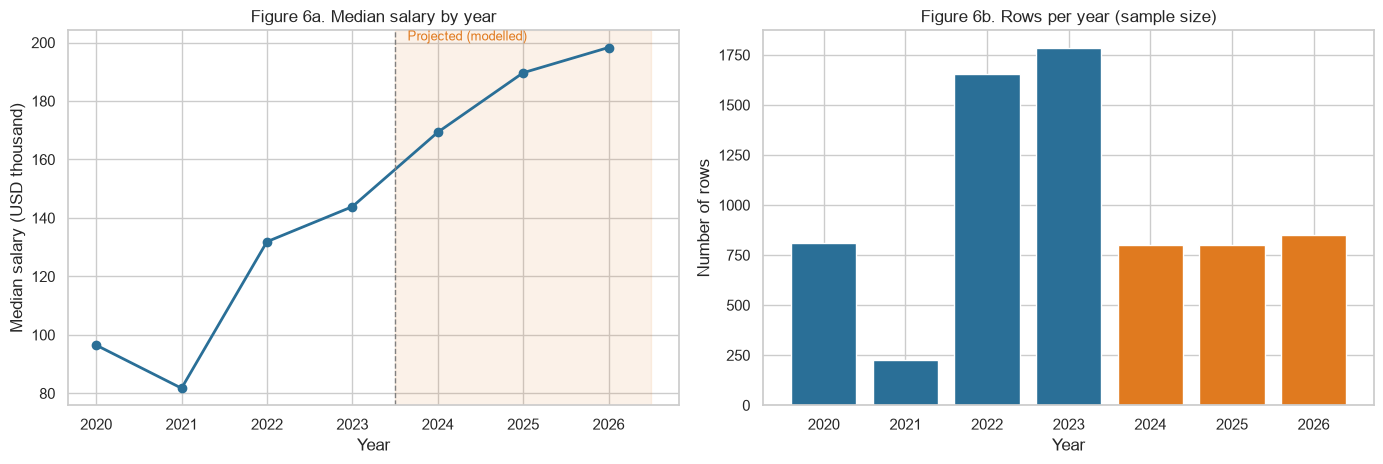

work_year,2020,2021,2022,2023,2024,2025,2026
median_salary,96500.0,81750.0,131876.0,143860.0,169315.5,189671.0,198309.5
rows,810.0,224.0,1654.0,1783.0,800.0,800.0,850.0


In [18]:
# Figure 6 - median salary per year (line) and number of rows per year (bars)
by_year = jobs.groupby("work_year").agg(median_salary=("salary_usd", "median"), rows=("job_id", "count"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(by_year.index, by_year["median_salary"] / 1000, marker="o", color=C_OBS, lw=2)
axes[0].set(title="Figure 6a. Median salary by year", xlabel="Year", ylabel="Median salary (USD thousand)")
shade_projection(axes[0])
axes[1].bar(by_year.index, by_year["rows"], color=[C_OBS if y <= 2023 else C_PROJ for y in by_year.index])
axes[1].set(title="Figure 6b. Rows per year (sample size)", xlabel="Year", ylabel="Number of rows")
plt.tight_layout(); plt.show()
display(by_year.T)

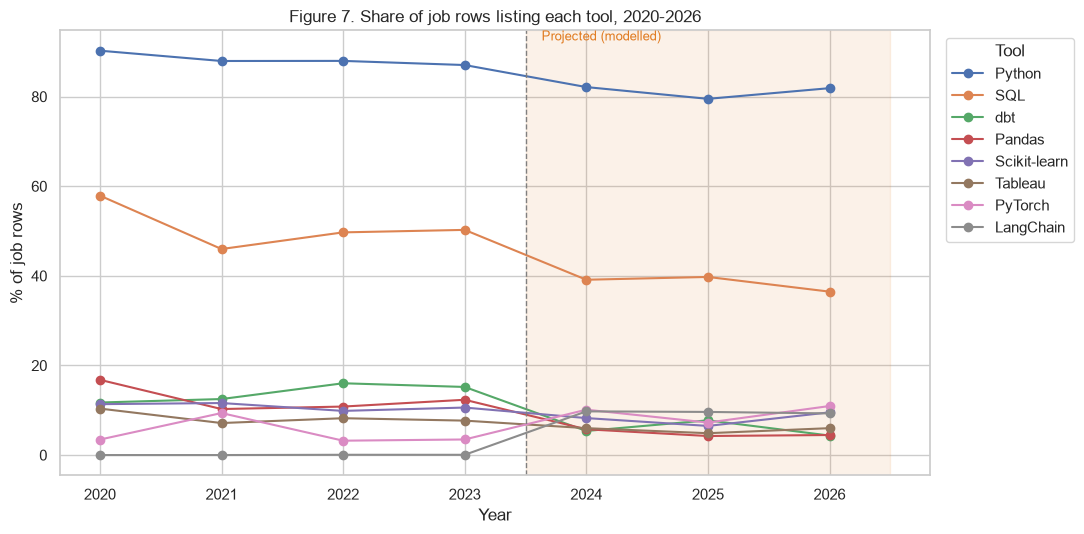

work_year,2020,2021,2022,2023,2024,2025,2026
Python,90.2,87.9,88.0,87.0,82.1,79.5,81.9
SQL,57.9,46.0,49.7,50.3,39.1,39.8,36.5
dbt,11.7,12.5,16.0,15.2,5.4,7.8,4.4
Pandas,16.8,10.3,10.8,12.3,5.8,4.2,4.5
Scikit-learn,11.4,11.6,9.9,10.6,8.2,6.5,9.5
Tableau,10.4,7.1,8.2,7.7,6.0,4.9,6.0
PyTorch,3.5,9.4,3.2,3.5,10.1,7.2,10.9
LangChain,0.0,0.0,0.1,0.1,9.8,9.6,9.3


In [19]:
# Figure 7 - how the share of jobs listing each tool changes over time (line chart)
trend_tools = ["Python", "SQL", "dbt", "Pandas", "Scikit-learn", "Tableau", "PyTorch", "LangChain"]
year_share = {t: jobs.groupby("work_year")["tool_list"].apply(lambda s, t=t: s.apply(lambda lst: t in lst).mean() * 100)
              for t in trend_tools}
year_share = pd.DataFrame(year_share)

fig, ax = plt.subplots(figsize=(11, 5.5))
for t in trend_tools:
    ax.plot(year_share.index, year_share[t], marker="o", label=t)
ax.set(title="Figure 7. Share of job rows listing each tool, 2020-2026", xlabel="Year", ylabel="% of job rows")
shade_projection(ax)
ax.legend(title="Tool", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()
display(year_share.round(1).T)

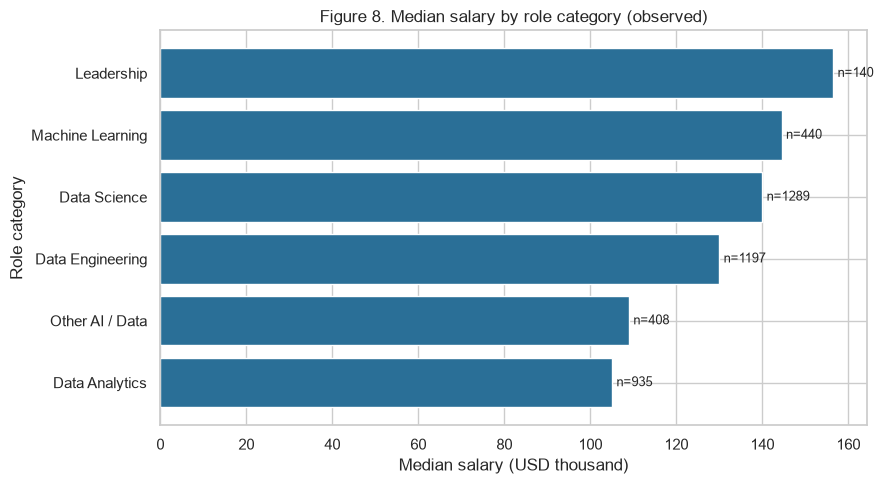

In [20]:
# Figure 8 - median salary by role category (observed data, categories with at least 30 rows)
role_stats = obs.groupby("ai_role_category")["salary_usd"].agg(["count", "median"]).query("count >= 30").sort_values("median")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(role_stats.index, role_stats["median"] / 1000, color=C_OBS)
for i, (med, n) in enumerate(zip(role_stats["median"], role_stats["count"])):
    ax.text(med / 1000 + 1, i, f"n={n}", va="center", fontsize=9)
ax.set(title="Figure 8. Median salary by role category (observed)", xlabel="Median salary (USD thousand)", ylabel="Role category")
plt.tight_layout(); plt.show()

Tools tested: 31 | statistically significant after correction: 12


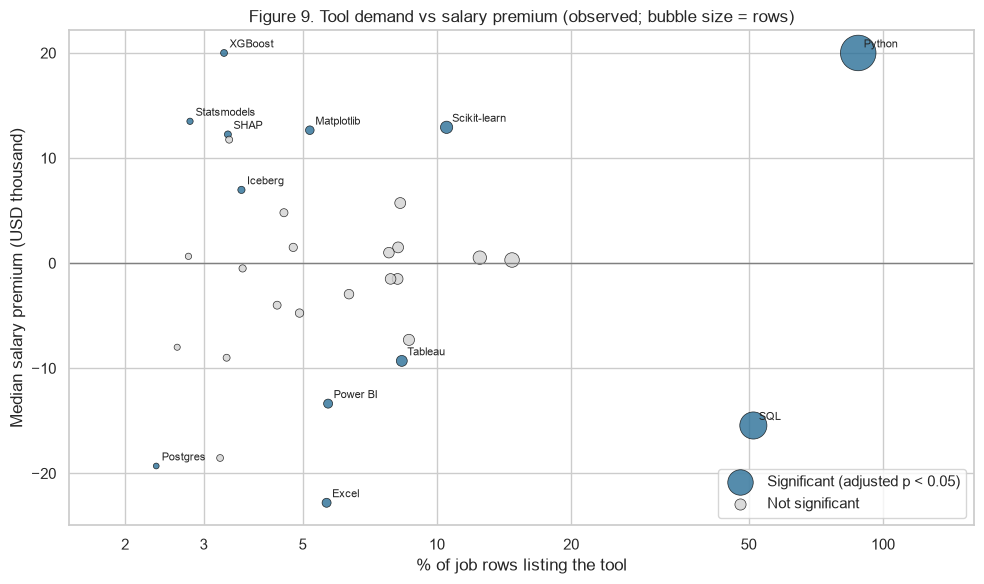

In [21]:
# Salary premium per tool: median salary of jobs listing the tool minus the median of jobs that do not (observed rows)
def tool_premium(df, min_n=100):
    counts = df["tool_list"].explode().value_counts()
    rows = []
    for tool in counts[counts >= min_n].index:
        has_tool = df["tool_list"].apply(lambda lst: tool in lst)
        with_t, without = df.loc[has_tool, "salary_usd"], df.loc[~has_tool, "salary_usd"]
        _, p = stats.mannwhitneyu(with_t, without, alternative="two-sided")      # non-parametric: salary is skewed
        rows.append({"tool": tool, "rows_with_tool": int(has_tool.sum()), "share_pct": has_tool.mean() * 100,
                     "median_with": with_t.median(), "median_without": without.median(),
                     "premium_usd": with_t.median() - without.median(), "p_value": p})
    res = pd.DataFrame(rows)
    try:
        res["p_adj"] = stats.false_discovery_control(res["p_value"])              # Benjamini-Hochberg, many tests at once
    except AttributeError:
        res["p_adj"] = (res["p_value"] * len(res)).clip(upper=1)                 # Bonferroni fallback for old SciPy
    res["significant"] = res["p_adj"] < 0.05
    return res.sort_values("premium_usd", ascending=False).reset_index(drop=True)

premium = tool_premium(obs)
print("Tools tested:", len(premium), "| statistically significant after correction:", int(premium["significant"].sum()))

# Figure 9 - scatter: how common is the tool vs the salary premium it carries
fig, ax = plt.subplots(figsize=(10, 6))
for flag, colour, label in [(True, C_OBS, "Significant (adjusted p < 0.05)"), (False, "lightgray", "Not significant")]:
    sub = premium[premium["significant"] == flag]
    ax.scatter(sub["share_pct"], sub["premium_usd"] / 1000, s=sub["rows_with_tool"] / 6, color=colour,
               alpha=0.8, edgecolor="black", linewidth=0.5, label=label)
for _, r in premium.iterrows():
    if r["significant"] or r["share_pct"] > 15:
        ax.annotate(r["tool"], (r["share_pct"], r["premium_usd"] / 1000), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.axhline(0, color="gray", lw=1)
ax.set(title="Figure 9. Tool demand vs salary premium (observed; bubble size = rows)",
       xlabel="% of job rows listing the tool", ylabel="Median salary premium (USD thousand)")
ax.set_xscale("log"); ax.set_xlim(1.5, 160)
ax.set_xticks([2, 3, 5, 10, 20, 50, 100]); ax.set_xticklabels(["2", "3", "5", "10", "20", "50", "100"])
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

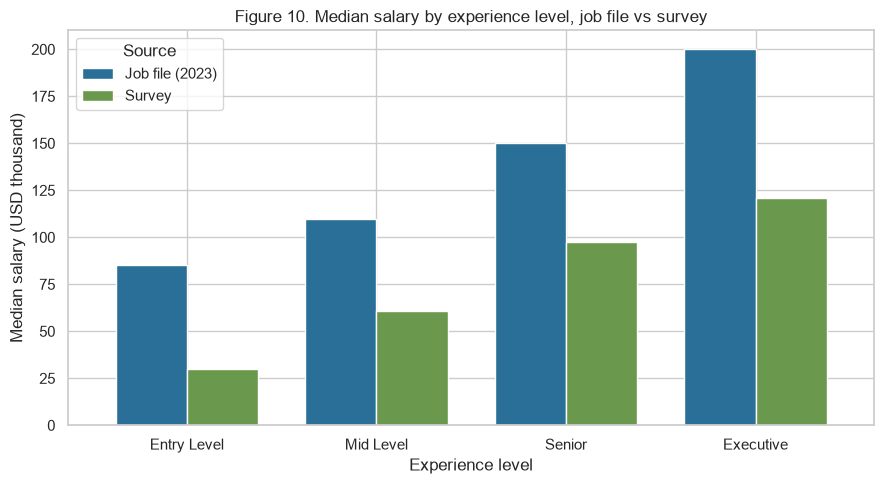

,Job file (2023),Survey,n job file,n survey
experience_level,,,,
Entry Level,85000.0,30058.0,116,26
Mid Level,109686.0,60728.0,320,98
Senior,150000.0,97557.0,1287,280
Executive,200000.0,120759.0,60,248


Caution: survey experience levels come from years worked (assumption: <3, 3-7, 8-19, 20+), and survey salaries are self-reported, so compare the pattern rather than the exact amounts.


In [22]:
# Figure 10 - salary by experience: job file (2023) vs survey respondents (two sources side by side)
cmp = pd.concat([
    jobs[jobs["work_year"] == 2023].groupby("experience_level", observed=True)["salary_usd"].median().rename("Job file (2023)"),
    survey.groupby("experience_level", observed=True)["salary_usd"].median().rename("Survey"),
], axis=1).reindex(EXP_ORDER)
n_cmp = pd.concat([jobs[jobs["work_year"] == 2023].groupby("experience_level", observed=True)["salary_usd"].count().rename("n job file"),
                   survey.groupby("experience_level", observed=True)["salary_usd"].count().rename("n survey")], axis=1).reindex(EXP_ORDER)

ax = (cmp / 1000).plot(kind="bar", color=[C_OBS, C_SUP], figsize=(9, 5), width=0.75)
ax.set(title="Figure 10. Median salary by experience level, job file vs survey",
       xlabel="Experience level", ylabel="Median salary (USD thousand)")
ax.tick_params(axis="x", rotation=0); ax.legend(title="Source")
plt.tight_layout(); plt.show()
display(pd.concat([cmp.round(0), n_cmp], axis=1))
print("Caution: survey experience levels come from years worked (assumption: <3, 3-7, 8-19, 20+), and survey salaries are self-reported, so compare the pattern rather than the exact amounts.")

## 3.3 Multivariate analysis
**Step:** look at three or more variables together - region x experience and role x experience salary heatmaps (pivot tables), which tools appear together, correlations between the numeric and ordered variables, how the mix of roles changes by year, and the demand vs supply gaps by skill and experience level.

experience_level,Entry Level,Mid Level,Senior,Executive
region,,,,
Africa,NaN,NaN,NaN,NaN
Asia Pacific,26.0,31.0,57.0,NaN
Europe,49.0,70.0,71.0,127.0
Latin America,NaN,51.0,NaN,NaN
Middle East,NaN,NaN,NaN,NaN
North America,90.0,101.0,147.0,200.0
Other,50.0,39.0,59.0,NaN


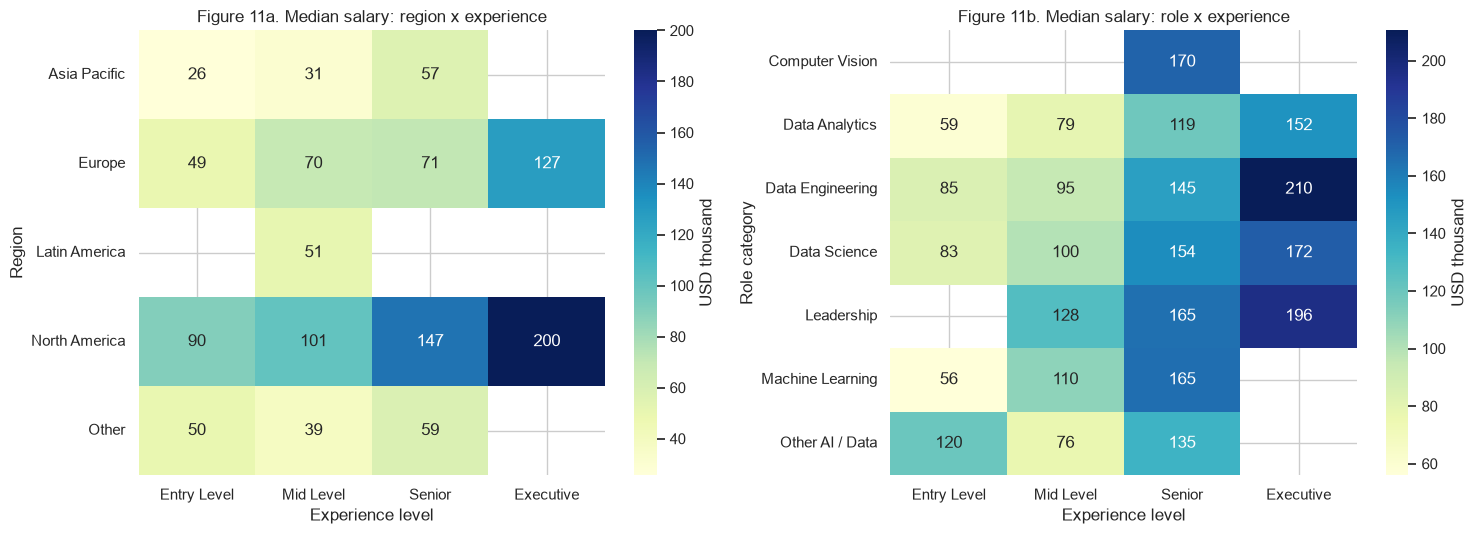

Blank cells have fewer than 10 rows; regions and roles with no cell of 10 rows are left out of the charts.


In [23]:
# Pivot tables + heatmaps: median salary (USD thousand), observed data, cells with at least 10 rows
def pivot_median(df, index, columns, min_n=10):
    med = df.pivot_table(index=index, columns=columns, values="salary_usd", aggfunc="median", observed=True)
    cnt = df.pivot_table(index=index, columns=columns, values="salary_usd", aggfunc="count", observed=True)
    return med.where(cnt >= min_n), cnt

reg_med, reg_cnt = pivot_median(obs, "region", "experience_level")
role_med, role_cnt = pivot_median(obs, "ai_role_category", "experience_level")
display((reg_med / 1000).round(0))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap((reg_med / 1000).dropna(how="all"), annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "USD thousand"}, ax=axes[0])
axes[0].set(title="Figure 11a. Median salary: region x experience", xlabel="Experience level", ylabel="Region")
sns.heatmap((role_med / 1000).dropna(how="all"), annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "USD thousand"}, ax=axes[1])
axes[1].set(title="Figure 11b. Median salary: role x experience", xlabel="Experience level", ylabel="Role category")
plt.tight_layout(); plt.show()
print("Blank cells have fewer than 10 rows; regions and roles with no cell of 10 rows are left out of the charts.")

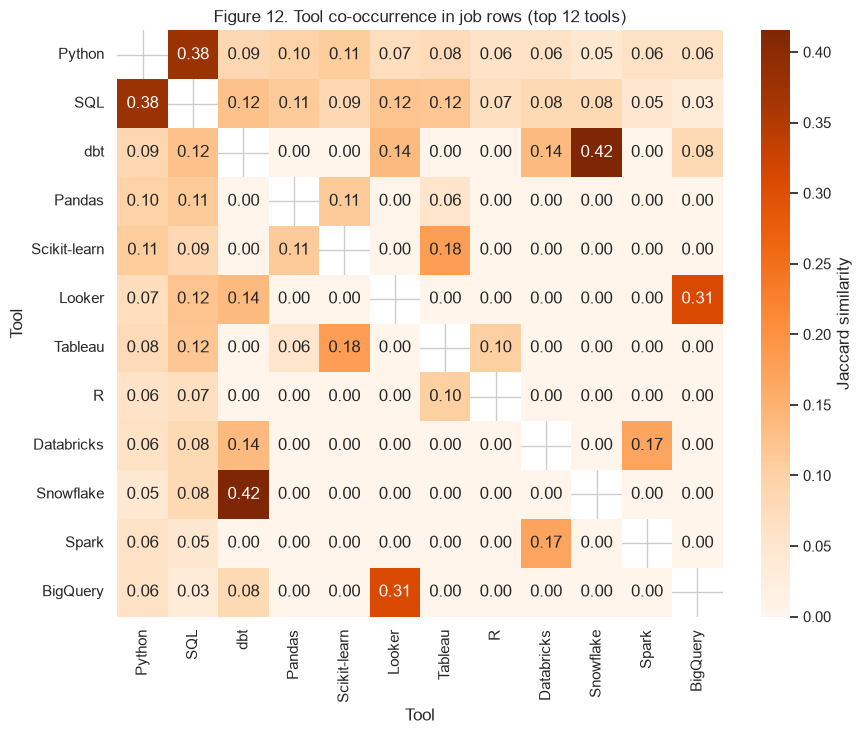

In [24]:
# Figure 12 - which tools are listed together? (Jaccard similarity between the 12 most common tools)
top12 = tools_long["tool"].value_counts().head(12).index
onehot = pd.crosstab(tools_long["job_id"], tools_long["tool"])[top12].clip(upper=1)
inter = onehot.T.dot(onehot)
union = onehot.sum().values[:, None] + onehot.sum().values[None, :] - inter
jaccard = inter / union
jaccard = jaccard.where(~np.eye(len(jaccard), dtype=bool))      # hide the diagonal (a tool with itself)

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(jaccard, annot=True, fmt=".2f", cmap="Oranges", cbar_kws={"label": "Jaccard similarity"}, ax=ax)
ax.set(title="Figure 12. Tool co-occurrence in job rows (top 12 tools)", xlabel="Tool", ylabel="Tool")
plt.tight_layout(); plt.show()

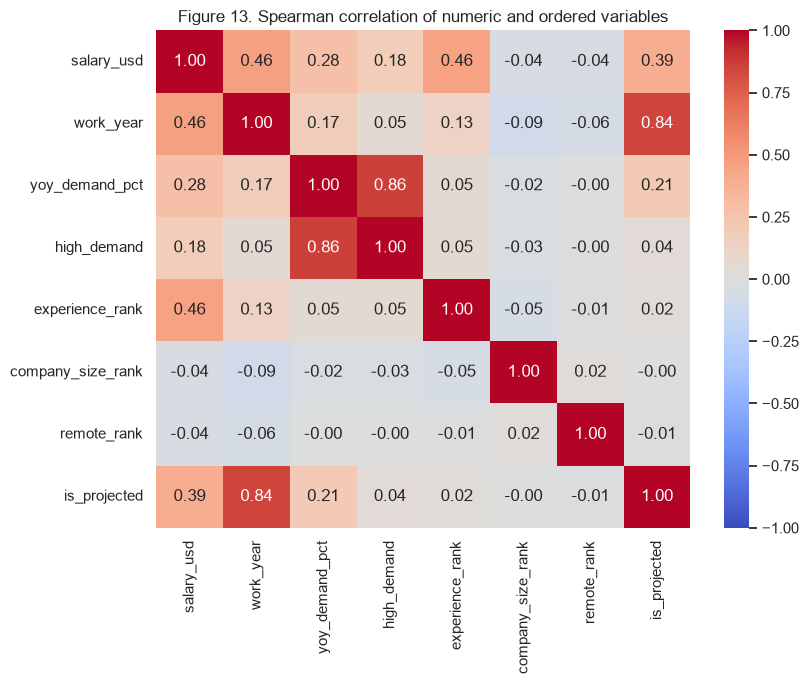

In [25]:
# Figure 13 - correlation heatmap (Spearman, because several variables are ordered categories)
enc = pd.DataFrame({
    "salary_usd":        jobs["salary_usd"],
    "work_year":         jobs["work_year"],
    "yoy_demand_pct":    jobs["yoy_demand_pct"],
    "high_demand":       jobs["high_demand"].astype(int),
    "experience_rank":   jobs["experience_level"].cat.codes + 1,                 # 1 = Entry ... 4 = Executive
    "company_size_rank": jobs["company_size"].cat.codes + 1,                     # 1 = Small ... 3 = Large
    "remote_rank":       jobs["remote_type"].map({"On-site": 0, "Hybrid": 1, "Remote": 2}),
    "is_projected":      (jobs["period"] == "Projected").astype(int),
})
corr = enc.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set(title="Figure 13. Spearman correlation of numeric and ordered variables")
plt.tight_layout(); plt.show()

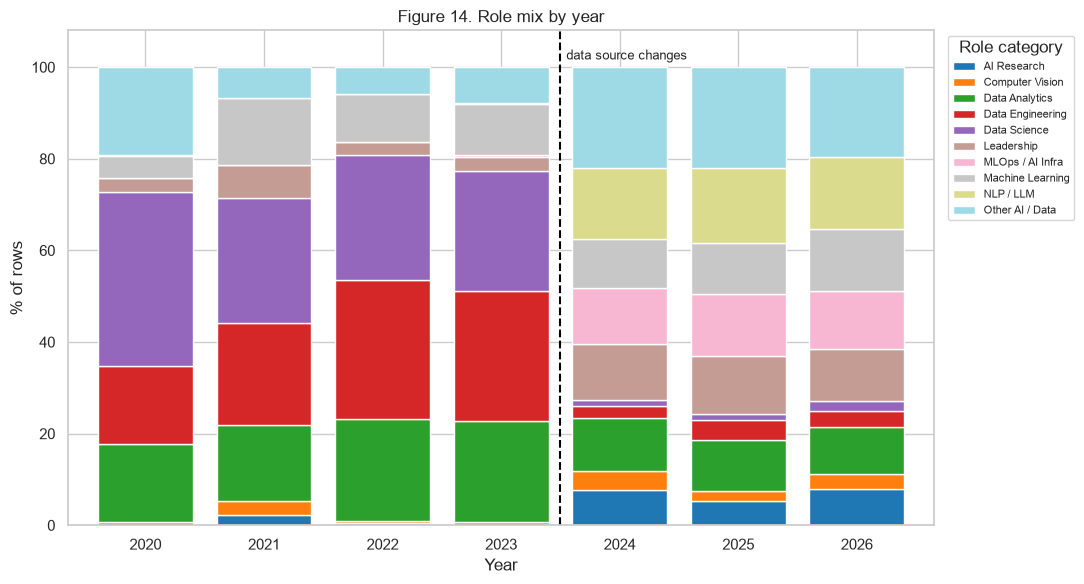

In [26]:
# Figure 14 - role mix by year (100% stacked bars): shows the change when the data switches from observed to projected
role_mix = pd.crosstab(jobs["work_year"], jobs["ai_role_category"], normalize="index") * 100
ax = role_mix.plot(kind="bar", stacked=True, figsize=(11, 6), colormap="tab20", width=0.8)
ax.axvline(3.5, color="black", ls="--", lw=1.5)
ax.text(3.55, 101, "data source changes", fontsize=9, va="bottom")
ax.set(title="Figure 14. Role mix by year", xlabel="Year", ylabel="% of rows", ylim=(0, 108))
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Role category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

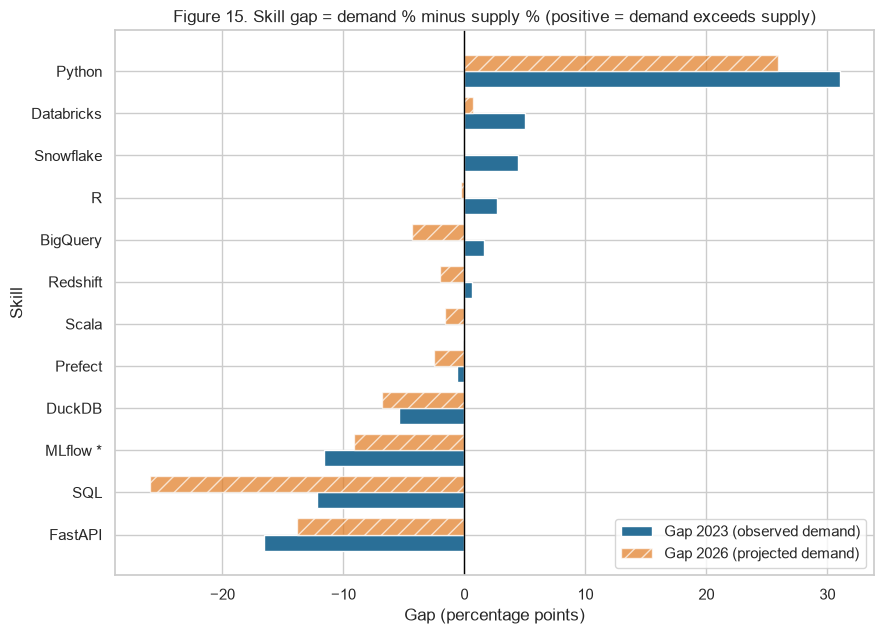

* = fewer than 150 survey respondents answered that question (low confidence).


In [27]:
# Figure 15 - demand-supply gap by skill, 2023 (observed demand) vs 2026 (projected demand)
g = gap.sort_values("gap_pp_2023")
labels = [s + (" *" if low else "") for s, low in zip(g["skill"], g["low_confidence"])]
y = np.arange(len(g)); h = 0.38
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(y - h / 2, g["gap_pp_2023"], h, color=C_OBS, label="Gap 2023 (observed demand)")
ax.barh(y + h / 2, g["gap_pp_2026"], h, color=C_PROJ, alpha=0.7, hatch="//", label="Gap 2026 (projected demand)")
ax.axvline(0, color="black", lw=1)
ax.set_yticks(y); ax.set_yticklabels(labels)
ax.set(title="Figure 15. Skill gap = demand % minus supply % (positive = demand exceeds supply)",
       xlabel="Gap (percentage points)", ylabel="Skill")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()
print("* = fewer than 150 survey respondents answered that question (low confidence).")

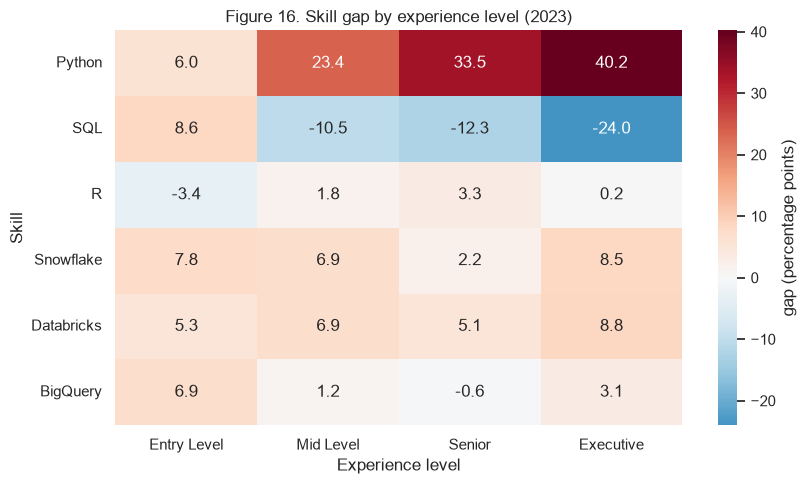

,job rows (2023),survey respondents
experience_level,,
Entry Level,116,81
Mid Level,320,146
Senior,1287,355
Executive,60,400


Caution: the survey has few entry-level and mid-level respondents, so those columns are less reliable.


In [28]:
# Figure 16 - skill gap by experience level (2023 demand vs survey supply), core skills
core = ["Python", "SQL", "R", "Snowflake", "Databricks", "BigQuery"]
gap_by_level, n_rows = {}, []
for lvl in EXP_ORDER:
    j_sub = jobs[(jobs["work_year"] == 2023) & (jobs["experience_level"] == lvl)]
    s_sub = survey[survey["experience_level"] == lvl]
    gap_by_level[lvl] = skill_gap(j_sub, s_sub).set_index("skill")["gap_pp"]
    n_rows.append({"experience_level": lvl, "job rows (2023)": len(j_sub), "survey respondents": len(s_sub)})
gap_level = pd.DataFrame(gap_by_level).loc[core]

fig, ax = plt.subplots(figsize=(8.5, 5))
sns.heatmap(gap_level, annot=True, fmt=".1f", cmap="RdBu_r", center=0, cbar_kws={"label": "gap (percentage points)"}, ax=ax)
ax.set(title="Figure 16. Skill gap by experience level (2023)", xlabel="Experience level", ylabel="Skill")
plt.tight_layout(); plt.show()
display(pd.DataFrame(n_rows).set_index("experience_level"))
print("Caution: the survey has few entry-level and mid-level respondents, so those columns are less reliable.")

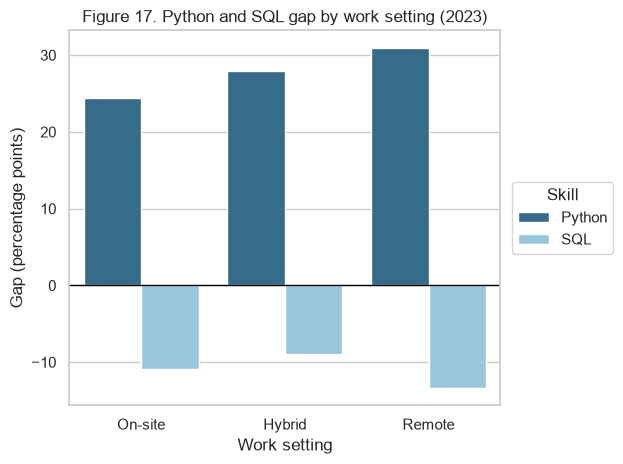

skill,Python,SQL
work_setting,,
Hybrid,28.0,-9.0
On-site,24.4,-10.9
Remote,31.0,-13.4


In [29]:
# Figure 17 - the same skills, supply vs demand by work setting (job file 2023 vs survey)
rows = []
for setting in ["On-site", "Hybrid", "Remote"]:
    j_sub = jobs[(jobs["work_year"] == 2023) & (jobs["remote_type"] == setting)]
    s_sub = survey[survey["remote_type"] == setting]
    r = skill_gap(j_sub, s_sub).set_index("skill")["gap_pp"].loc[["Python", "SQL"]]
    for skill, val in r.items():
        rows.append({"work_setting": setting, "skill": skill, "gap_pp": val, "n_jobs": len(j_sub), "n_survey": len(s_sub)})
gap_setting = pd.DataFrame(rows)
ax = sns.barplot(data=gap_setting, x="work_setting", y="gap_pp", hue="skill", palette=["#2a6f97", "#8ecae6"])
ax.axhline(0, color="black", lw=1)
ax.set(title="Figure 17. Python and SQL gap by work setting (2023)", xlabel="Work setting", ylabel="Gap (percentage points)")
ax.legend(title="Skill", loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(); plt.show()
display(gap_setting.pivot(index="work_setting", columns="skill", values="gap_pp").round(1))

# PHASE 4 - Statistical analysis
Charts show patterns; tests tell us whether a pattern is larger than we would expect by chance. Because salary is right-skewed (Figure 1), we use **non-parametric** tests (Kruskal-Wallis, Spearman, Mann-Whitney) that do not assume a normal distribution.

| Question | Test |
|---|---|
| 4.1 Does salary rise with experience? | Kruskal-Wallis and Spearman correlation |
| 4.2 Which tools carry a salary premium? | Mann-Whitney U per tool, corrected for many tests |
| 4.3 Did the data change more at 2023 -> 2024 than in a normal year? | Chi-square and Cramer's V (effect size) |
| 4.4 How do tool shares change inside the projected years? | Chi-square per tool, 2024 vs 2026 |

In [30]:
# 4.1 Salary vs experience (observed rows)
groups = [g["salary_usd"].values for _, g in obs.groupby("experience_level", observed=True)]
H, p_kw = stats.kruskal(*groups)
rho, p_rho = stats.spearmanr(obs["experience_level"].cat.codes, obs["salary_usd"])
print(f"Kruskal-Wallis: H = {H:.1f}, p = {p_kw:.3g}")
print(f"Spearman rho (experience rank vs salary) = {rho:.2f}, p = {p_rho:.3g}")

# the same check on the survey (years worked vs salary)
sv = survey.dropna(subset=["WorkExp", "salary_usd"])
rho_s, p_s = stats.spearmanr(sv["WorkExp"], sv["salary_usd"])
print(f"Survey: Spearman rho (years worked vs salary) = {rho_s:.2f}, p = {p_s:.3g}, n = {len(sv)}")

Kruskal-Wallis: H = 1056.3, p = 1.08e-228
Spearman rho (experience rank vs salary) = 0.49, p = 1.95e-263
Survey: Spearman rho (years worked vs salary) = 0.40, p = 9.77e-27, n = 652


In [31]:
# 4.2 Salary premium per tool (table computed above)
cols = ["tool", "rows_with_tool", "share_pct", "median_with", "median_without", "premium_usd", "p_adj", "significant"]
print("Largest premiums:")
display(premium[cols].head(8).round({"share_pct": 1, "median_with": 0, "median_without": 0, "premium_usd": 0, "p_adj": 4}))
print("Largest discounts:")
display(premium[cols].tail(5).round({"share_pct": 1, "median_with": 0, "median_without": 0, "premium_usd": 0, "p_adj": 4}))

Largest premiums:


,tool,rows_with_tool,share_pct,median_with,median_without,premium_usd,p_adj,significant
0,Python,3935,88.0,130000.0,110000.0,20000.0,0.0000,True
1,XGBoost,149,3.3,148000.0,128000.0,20000.0,0.0020,True
2,Statsmodels,125,2.8,141525.0,128029.0,13496.0,0.0459,True
3,Scikit-learn,470,10.5,140000.0,127075.0,12925.0,0.0005,True
4,Matplotlib,232,5.2,140650.0,128000.0,12650.0,0.0245,True
5,SHAP,152,3.4,140250.0,128000.0,12250.0,0.0231,True
6,MLflow,153,3.4,140250.0,128500.0,11750.0,0.1353,False
7,Iceberg,163,3.6,135000.0,128029.0,6971.0,0.0231,True


Largest discounts:


,tool,rows_with_tool,share_pct,median_with,median_without,premium_usd,p_adj,significant
26,Power BI,255,5.7,115934.0,129300.0,-13366.0,0.0231,True
27,SQL,2290,51.2,120000.0,135446.0,-15446.0,0.0000,True
28,Jupyter,146,3.3,110762.0,129300.0,-18538.0,0.1353,False
29,Postgres,105,2.3,110000.0,129300.0,-19300.0,0.0245,True
30,Excel,253,5.7,106500.0,129300.0,-22800.0,0.0000,True


In [32]:
# 4.3 Break-point test: compare how much the data changes from one year to the next
# 2022->2023 = both observed (a normal year), 2023->2024 = the data source changes, 2024->2026 = both projected
def cramers_v(table):
    chi2 = stats.chi2_contingency(table)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

def change_effect(col, y1, y2):
    sub = jobs[jobs["work_year"].isin([y1, y2])]
    table = pd.crosstab(sub["work_year"], sub[col])
    return cramers_v(table), stats.chi2_contingency(table)[1]

rows = []
for col in ["ai_role_category", "region", "experience_level", "ai_disruption_risk", "remote_type", "company_size"]:
    v1, _ = change_effect(col, 2022, 2023)
    v2, p2 = change_effect(col, 2023, 2024)
    v3, _ = change_effect(col, 2024, 2026)
    rows.append({"variable": col, "V 2022->2023 (normal year)": v1, "V 2023->2024 (source change)": v2,
                 "V 2024->2026 (projected years)": v3, "p-value 2023->2024": p2})
break_table = pd.DataFrame(rows).set_index("variable")
display(break_table.round(3))

med = jobs.groupby("work_year")["salary_usd"].median()
print("Median salary change: 2022->2023 {:+.1%} | 2023->2024 {:+.1%} | 2024->2026 {:+.1%}".format(
    med[2023] / med[2022] - 1, med[2024] / med[2023] - 1, med[2026] / med[2024] - 1))

,V 2022->2023 (normal year),V 2023->2024 (source change),V 2024->2026 (projected years),p-value 2023->2024
variable,,,,
ai_role_category,0.068,0.676,0.074,0.0
region,0.107,0.353,0.060,0.0
experience_level,0.054,0.128,0.029,0.0
ai_disruption_risk,0.013,0.374,0.038,0.0
remote_type,0.223,0.420,0.048,0.0
company_size,0.137,0.333,0.026,0.0


Median salary change: 2022->2023 +9.1% | 2023->2024 +17.7% | 2024->2026 +17.1%


**How to read Cramer's V:** 0 = no change in the mix, 1 = completely different mix. Values above about 0.3 are a large change. A p-value shown as 0.000 means p < 0.001. If the V for 2023 -> 2024 is much larger than for the other transitions, the jump comes from the change of data source (observed -> modelled), not from the job market. This is why the project keeps observed and projected years separate.

In [33]:
# 4.4 Inside the projected years: how do tool shares change from 2024 to 2026?
rows = []
y24, y26 = jobs[jobs["work_year"] == 2024], jobs[jobs["work_year"] == 2026]
for tool in ["Python", "SQL", "PyTorch", "LangChain", "dbt", "Spark", "Tableau", "Power BI", "Scikit-learn", "Databricks"]:
    a = y24["tool_list"].apply(lambda lst: tool in lst)
    b = y26["tool_list"].apply(lambda lst: tool in lst)
    table = [[a.sum(), (~a).sum()], [b.sum(), (~b).sum()]]
    rows.append({"tool": tool, "share 2024 %": a.mean() * 100, "share 2026 %": b.mean() * 100,
                 "change (pp)": (b.mean() - a.mean()) * 100, "p-value": stats.chi2_contingency(table)[1]})
proj_change = pd.DataFrame(rows).sort_values("change (pp)", ascending=False)
display(proj_change.round(3).reset_index(drop=True))

,tool,share 2024 %,share 2026 %,change (pp),p-value
0,Scikit-learn,8.250,9.529,1.279,0.409
1,PyTorch,10.125,10.941,0.816,0.646
2,Databricks,3.625,4.118,0.493,0.696
3,Tableau,6.000,6.000,0.000,1.000
4,Python,82.125,81.882,-0.243,0.949
5,Spark,3.625,3.294,-0.331,0.816
6,Power BI,5.625,5.294,-0.331,0.851
7,LangChain,9.750,9.294,-0.456,0.817
8,dbt,5.375,4.353,-1.022,0.395
9,SQL,39.125,36.471,-2.654,0.289


# PHASE 5 - Insights, summary and recommendations
The guideline asks for **at least 5 key insights, explained in your own words**, plus a short overall summary and recommendations. The cell below collects the key numbers from your own analysis so you can build each insight on evidence. Choose the five findings that you find most interesting, then write them up in the cells that follow.

In [34]:
# Evidence cell - numbers pulled from the analysis above (nothing here is typed in by hand)
share_all = tools_long["tool"].value_counts(normalize=False) / len(jobs) * 100
sal_med = jobs.groupby("work_year")["salary_usd"].median()
exp_med = obs.groupby("experience_level", observed=True)["salary_usd"].median()
best_gap = gap[~gap["low_confidence"]].sort_values("gap_pp_2023")
na_share = jobs.groupby("period")["region"].apply(lambda s: (s == "North America").mean() * 100)
remote_share = jobs.groupby("period")["remote_type"].apply(lambda s: (s == "Remote").mean() * 100)
sig_pos = premium[(premium["significant"]) & (premium["premium_usd"] > 0)]
sig_neg = premium[(premium["significant"]) & (premium["premium_usd"] < 0)]

print("E1  Most requested tools (all job rows):", ", ".join(f"{t} {v:.0f}%" for t, v in share_all.head(5).items()))
print(f"E2  Observed median salary {sal_med[2020]:,.0f} (2020) -> {sal_med[2023]:,.0f} (2023); projected {sal_med[2024]:,.0f} (2024) -> {sal_med[2026]:,.0f} (2026)")
print(f"E3  Median salary Entry {exp_med['Entry Level']:,.0f} vs Executive {exp_med['Executive']:,.0f} (observed); Spearman rho = {rho:.2f}")
print("E4  Significant salary premiums:", ", ".join(f"{r.tool} (+{r.premium_usd:,.0f})" for r in sig_pos.head(5).itertuples()) or "none")
print("    Significant salary discounts:", ", ".join(f"{r.tool} ({r.premium_usd:,.0f})" for r in sig_neg.head(5).itertuples()) or "none")
print("E5  Cramer's V for role mix: 2022->2023 = {:.2f}, 2023->2024 = {:.2f}, 2024->2026 = {:.2f}".format(
    *break_table.loc["ai_role_category", ["V 2022->2023 (normal year)", "V 2023->2024 (source change)", "V 2024->2026 (projected years)"]]))
print(f"E6  Largest skill shortage (2023, reliable skills): {best_gap.iloc[-1]['skill']} ({best_gap.iloc[-1]['gap_pp_2023']:+.1f} pp); "
      f"largest surplus: {best_gap.iloc[0]['skill']} ({best_gap.iloc[0]['gap_pp_2023']:+.1f} pp)")
print(f"E7  North America share of rows: observed {na_share['Observed']:.0f}% vs projected {na_share['Projected']:.0f}%")
print(f"E8  Remote share of rows: observed {remote_share['Observed']:.0f}% vs projected {remote_share['Projected']:.0f}%")

E1  Most requested tools (all job rows): Python 86%, SQL 47%, dbt 12%, Pandas 10%, Scikit-learn 10%
E2  Observed median salary 96,500 (2020) -> 143,860 (2023); projected 169,316 (2024) -> 198,310 (2026)
E3  Median salary Entry 72,750 vs Executive 196,000 (observed); Spearman rho = 0.49
E4  Significant salary premiums: Python (+20,000), XGBoost (+20,000), Statsmodels (+13,496), Scikit-learn (+12,925), Matplotlib (+12,650)
    Significant salary discounts: Tableau (-9,300), Power BI (-13,366), SQL (-15,446), Postgres (-19,300), Excel (-22,800)
E5  Cramer's V for role mix: 2022->2023 = 0.07, 2023->2024 = 0.68, 2024->2026 = 0.07
E6  Largest skill shortage (2023, reliable skills): Python (+31.0 pp); largest surplus: FastAPI (-16.6 pp)
E7  North America share of rows: observed 87% vs projected 67%
E8  Remote share of rows: observed 39% vs projected 26%


### Insight 1: Python is the most requested skill

**Python appears in 85.6% of all job rows, and in 88% of the observed years (2020–2023). SQL is second at about 47%.**
**Evidence: E1 and the most-requested-tools chart.**
**Why it matters: Anyone entering AI or data work needs Python first**

**insight 2: More experience means higher pay**

**In the observed years, the median salary is $72,750 for Entry level and $196,000 for Executive. The Spearman correlation is 0.49, and the survey shows the same direction at 0.40.**
**Evidence: E3 and section 4.1.**
**Why it matters: Two independent sources agree, so the link is not a replication of one dataset.**

### Key insight 3 - Python is the biggest skill shortage, and some skills are oversupplied

**In 2023, Python demand was 31 percentage points higher than the share of developers who use it. FastAPI (−16.6 pp) and SQL (−12 pp) show a surplus: more developers have them than jobs ask for.**
**Evidence: E6 and the demand vs supply gap chart.**
**Why it matters: Learners should put their time into skills with a shortage, not a surplus**.

### Insight 4: Some tools come with higher pay, others lower

**Jobs that list Python have a median salary of $130K, against $110K for jobs without it (+$20K). SQL (−$15.4K), Excel (−$22.8K) and Power BI (−$13.4K) go the other way. 12 of the 31 tools tested were significant after correcting for many tests.
Evidence: E4 and section 4.2.
Why it matters: Tools like SQL and Excel are probably common in lower-paid analyst roles. The tool itself does not cause the lower pay, so this shows patterns, not causes.**


### nsight 5: The jump from 2023 to 2024 comes from the data source, not the market

**The role mix changed very little from 2022 to 2023 (Cramér's V = 0.068), then jumped to 0.676 from 2023 to 2024. It went back to 0.074 across the projected years. The 2024–2026 rows are model-generated projections.**
**Evidence: E5 and section 4.3.
Why it matters: Observed and projected years must be kept separate, or a source change will be read as a market change.**

## Anomaly worth highlighting
The 2023→2024 break is the anomaly. I kept 2020–2023 (observed) and 2024–2026 (projected) apart in every comparison. The north america share (87% vs 67%) and remote share (39% vs 26%) also differ between the two groups, which supports this.

## Overall summary and recommendations - YOUR TURN
Python is the most requested and most under-supplied skill. Pay rises clearly with experience. Skills like SQL and Excel are common and carry no pay premium.

## Limitations 
- The job file is mostly a **salary survey**, so tool demand is a proxy for real postings, and it is heavily weighted to North America and senior roles.
- Rows for **2024-2026 are model-generated projections**, so findings for those years reflect the model's assumptions rather than observed behaviour.
- Only about 12 tools could be matched between the two sources; popular analytics tools (Pandas, Tableau, Power BI, Excel, Spark) do not exist in the survey, so their gaps cannot be measured.
- The survey file used here is a **1,000-row sample** of a much larger survey, and only about 14% of respondents hold data or AI roles, which makes supply estimates noisy.
- The two files describe **different populations** (job records vs developers), so gaps are indicators, not exact measurements. The experience, company-size and work-setting groupings are my own assumptions.

## Save the cleaned data
Cleaned files go in `cleaned/`. The original files in `raw_data/'

In [35]:
jobs.drop(columns=["tool_list"]).to_csv(OUT_DIR / "jobs_clean.csv", index=False)
tools_long.to_csv(OUT_DIR / "tools_long.csv", index=False)
survey.to_csv(OUT_DIR / "survey_clean.csv", index=False)
gap.to_csv(OUT_DIR / "skill_gap_preview.csv", index=False)
premium.to_csv(OUT_DIR / "tool_salary_premium.csv", index=False)
print("Saved:", sorted(p.name for p in OUT_DIR.iterdir()))

Saved: ['jobs_clean.csv', 'skill_gap_preview.csv', 'survey_clean.csv', 'tool_salary_premium.csv', 'tools_long.csv']


## Guideline checklist
| Guideline requirement | Where in this notebook |
|---|---|
| Data loading and initial overview (rows, columns, types, `head()`, `info()`, `describe()`) | Phase 1 |
| Missing values, duplicates, data types, derived columns, filtering/aggregating | Phase 2 |
| Univariate, bivariate and multivariate analysis; `groupby`, pivot tables, correlation; statistical summaries | Phase 3 (sections 3.1-3.3) and Phase 4 |
| At least 10 visualisations (bar, line, pie/donut, histogram, box, scatter, heatmap) with titles, labels, legends, subplots | Figures 1-17 |
| Markdown explanations of steps, decisions and interpretation | Throughout (see the YOUR TURN cells) |
| At least 5 key insights in your own words, anomalies, summary and recommendations | Phase 5 |
| Original raw data files, unchanged | `raw_data/` folder |